<a href="https://colab.research.google.com/github/ChayanikaAwasthi/bc-electricity-demand-analysis/blob/main/01_BC_Electricity_Demand_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Project 01: BC Electricity Demand Analysis**

**Objective**: Analyze historical electricity demand to identify daily, monthly and seasonal patterns.

In [ ]:
print("Hello, Power Systems!")
print("My first electricity data analysis project!")

Hello, Power Systems!
My first electricity data analysis project!


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving BalancingAuthorityLoad 2026.xls to BalancingAuthorityLoad 2026.xls


In [ ]:
#identify the uploaded file
file_name = list(uploaded.keys())[0]

#read the excel workbook
excel_file = pd.ExcelFile(file_name)

#display available sheets
print(excel_file.sheet_names)

['HourlyControlAreaLoadReport2025']


In [ ]:
df = pd.read_excel(file_name, sheet_name=0)
df.head()

,Hourly Control Area Load Report,Unnamed: 1,Unnamed: 2
0,Date Range:,-2026,NaN
1,Area Group Name:,BCHA,NaN
2,Date,HE,Control Area Load
3,01/01/2026,1,8188
4,01/01/2026,2,8091


In [ ]:
print(file_name)
print(excel_file.sheet_names)

BalancingAuthorityLoad 2026.xls
['HourlyControlAreaLoadReport2025']


In [ ]:
print(df.columns.tolist())

['Hourly Control Area Load Report', 'Unnamed: 1', 'Unnamed: 2']


In [ ]:
df_raw = pd.read_excel(file_name, header =None)
display(df_raw.head(20))

,0,1,2
0,Hourly Control Area Load Report,NaN,NaN
1,Date Range:,-2026,NaN
2,Area Group Name:,BCHA,NaN
3,Date,HE,Control Area Load
4,01/01/2026,1,8188
5,01/01/2026,2,8091
6,01/01/2026,3,8001
7,01/01/2026,4,7942
8,01/01/2026,5,7956
9,01/01/2026,6,8080


In [ ]:
df = pd.read_excel(file_name, header = 3)
display(df.head())

,Date,HE,Control Area Load
0,01/01/2026,1,8188
1,01/01/2026,2,8091
2,01/01/2026,3,8001
3,01/01/2026,4,7942
4,01/01/2026,5,7956


In [ ]:
print(df.columns.tolist())

['Date ', 'HE', 'Control Area Load']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7295 entries, 0 to 7294
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Date               7295 non-null   object
 1   HE                 7295 non-null   int64 
 2   Control Area Load  7295 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 171.1+ KB


A. Understanding and Cleaning the Dataset

In [ ]:
df.columns = df.columns.astype(str).str.strip()
print(df['Date'].min())
print(df['Date'].max())

01/01/2026
10/31/2026


In [ ]:
#Understanding the size of the dataset (how many roas and columns)
print("Dataset dimensions:", df.shape)

#Inspect Columns
print(df.columns.tolist())

#Check data types
df.info()

#Check missing values
df.isnull().sum()

#Check any duplicates
df.duplicated().sum()


Dataset dimensions: (7295, 3)
['Date', 'HE', 'Control Area Load']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7295 entries, 0 to 7294
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Date               7295 non-null   object
 1   HE                 7295 non-null   int64 
 2   Control Area Load  7295 non-null   int64 
dtypes: int64(2), object(1)
memory usage: 171.1+ KB


np.int64(0)

In [ ]:
#Descriptive Statistics
df["Control Area Load"].describe()

,Control Area Load
count,7295.000000
mean,7521.978890
std,1061.630174
min,5549.000000
25%,6841.000000
50%,7461.000000
75%,8189.500000
max,10823.000000


In [ ]:
#Find the max demand
max_idx = df["Control Area Load"].idxmax()
peak_demand = df.loc[max_idx]

print(peak_demand)

Date                 01/26/2026
HE                           18
Control Area Load         10823
Name: 617, dtype: object


In [ ]:
#Find the min demand
min_idx = df["Control Area Load"].idxmin()
min_demand = df.loc[min_idx]

print(min_demand)

Date                 07/01/2026
HE                            5
Control Area Load          5549
Name: 4347, dtype: object


B. Monthly Demand Patterns

In [34]:
#Monthly Demand Patterns

#Convert the date column into a proper daterime format
df["Date"] = pd.to_datetime(df["Date"])

#Group the data by month and calculate avg electricity demand
monthly_avg = df.groupby(df["Date"].dt.to_period("M"))["Control Area Load"].mean()

print(monthly_avg)

Date
2026-01    8918.860215
2026-02    8562.089286
2026-03    8184.016151
2026-04    7289.336111
2026-05    6867.461022
2026-06    6991.923611
2026-07    7207.012097
2026-08    7149.541667
2026-09    6882.273611
2026-10    7223.581989
Freq: M, Name: Control Area Load, dtype: float64


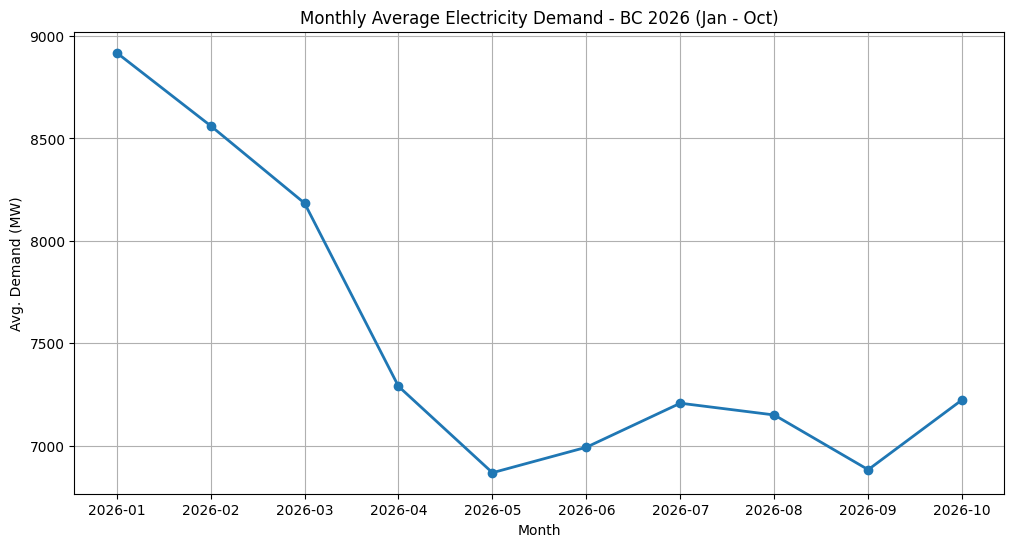

In [44]:
#Visualizing the monthly averages

#Setting the size of the graph
plt.figure(figsize=(12,6))

#Plotting monthly avg. electricty demand
plt.plot(monthly_avg.index.astype(str), monthly_avg.values, marker="o", linewidth=2)

#Adding a title to the graph
plt.title("Monthly Average Electricity Demand - BC 2026 (Jan - Oct)")

#Labeling the horizontal and vertical axes
plt.xlabel("Month")
plt.ylabel("Avg. Demand (MW)")

#Adding a grid to make values easier to read
plt.grid(True)

#Displaying the graph
plt.show()

C. Hourly Demand Patters

In [45]:
#Group the observation by Hour Ending (HE)
#Calculate the avg electricity demand for each hour
hourly_avg = df.groupby("HE")["Control Area Load"].mean()

#Display the avg demand for each hour
print(hourly_avg)

HE
1     6713.851974
2     6532.452145
3     6403.154605
4     6354.273026
5     6404.171053
6     6626.052632
7     7049.825658
8     7558.039474
9     7826.963816
10    7938.546053
11    7983.575658
12    7998.661184
13    8005.111842
14    7975.575658
15    7937.302632
16    7970.049342
17    8118.983553
18    8308.661184
19    8281.394737
20    8179.365132
21    8046.930921
22    7824.115132
23    7434.345395
24    7052.835526
Name: Control Area Load, dtype: float64


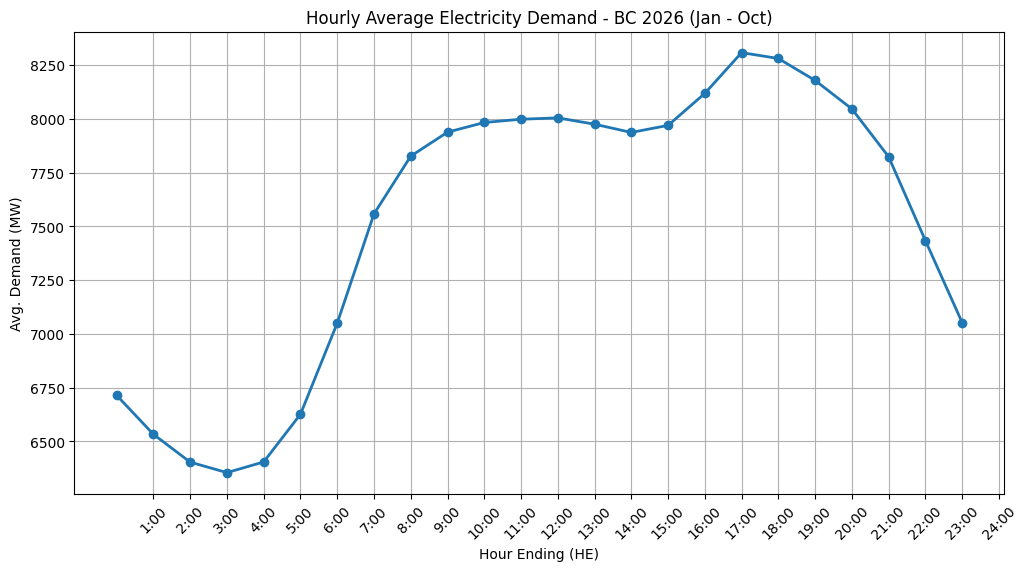

In [58]:
#Visualizing the hourly averages

#Setting the size of the graph
plt.figure(figsize=(12,6))

#Plotting hourly avg. electricty demand
plt.plot(hourly_avg.index.astype(str), hourly_avg.values, marker="o", linewidth=2)

#Adding a title to the graph
plt.title("Hourly Average Electricity Demand - BC 2026 (Jan - Oct)")

#Labeling the horizontal and vertical axes
plt.xlabel("Hour Ending (HE)")
plt.ylabel("Avg. Demand (MW)")

#Create time labels from the hour ending values
hour_labels =[f"{hour}:00" for hour in hourly_avg.index]
# Display all 24 hrs on the x-axis
plt.xticks(hourly_avg.index, hour_labels, rotation = 45)

#Adding a grid to make values easier to read
plt.grid(True)

#Displaying the graph
plt.show()
